# Data viz / exploration — OpenF1 API

Objective: To understand what the data looks like
before building the stint optimizer.

Selected endpoints: `stints`, `laps`, `pit`, `weather`, `drivers` — only what is strictly necessary
to model tire wear. Doc: https://openf1.org/

Loading and cleaning live in `app/f1data.py`, not in this notebook. The lap table analysed from
section 7 on used to be built in three different cells here, which is one table that can diverge
from itself; `f1data.build_base()` is now the only place it is built, and the baseline notebook of
phase 2 reads that same table.

## 1. Setup

`f1data` carries the cached OpenF1 client, the lap cleaning, the neutralised laps and
`build_base()`. What stays in this notebook is the analysis.

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import f1data
from f1data import COMPOUNDS

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")


## 2. Loading

One request per run and per endpoint, followed by concatenation. The first run downloads
(a few minutes); subsequent runs read from the cache.

In [56]:
sessions_2025 = f1data.load_sessions([2025])
races_2025 = f1data.held_races(sessions_2025)
print(f"{len(races_2025)} races in 2025")

data = {ep: f1data.by_session(ep, races_2025["session_key"])
        for ep in ["stints", "laps", "pit", "weather", "drivers"]}
for ep, df in data.items():
    print(f"{ep:9s} {df.shape}")


24 races in 2025


C:\Users\natha\Documents\formula1-stint-optimizer\app\f1data.py:147: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


stints    (1318, 8)
laps      (26265, 16)
pit       (821, 8)
weather   (3760, 10)
drivers   (479, 12)


## 3. Columns profile

For each endpoint: type, missing values, cardinality, min/max, example.

In [57]:
def profile(df, name=""):
    """Summary by column. The list columns (segments_sector_*) are neither
    comparable nor hashable: min/max and n_unique are None for these columns."""
    rows = []
    for col in df.columns:
        s, non_null = df[col], df[col].dropna()
        try:
            mn, mx = (non_null.min(), non_null.max()) if len(non_null) else (None, None)
        except (TypeError, ValueError):
            mn = mx = None
        try:
            nu = int(s.nunique())
        except (TypeError, ValueError):
            nu = None
        rows.append({
            "column": col, "dtype": str(s.dtype),
            "n_null": int(s.isna().sum()), "%_null": round(100 * s.isna().mean(), 1),
            "n_unique": nu, "min": mn, "max": mx,
            "example": str(non_null.iloc[0])[:55] if len(non_null) else None,
        })
    print(f"=== {name}: {df.shape[0]} rows x {df.shape[1]} columns ===")
    return pd.DataFrame(rows)


for ep, df in data.items():
    display(profile(df, ep))

=== stints: 1318 rows x 8 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,meeting_key,int64,0,0.0,24,1254,1277,1254
1,session_key,int64,0,0.0,24,9693,10033,9693
2,stint_number,int64,0,0.0,7,1,7,1
3,driver_number,int64,0,0.0,21,1,87,18
4,lap_start,float64,6,0.5,65,1.0,77.0,1.0
5,lap_end,float64,6,0.5,76,0.0,78.0,2.0
6,compound,object,0,0.0,4,HARD,SOFT,INTERMEDIATE
7,tyre_age_at_start,int64,0,0.0,36,0,54,0


=== laps: 26265 rows x 16 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,meeting_key,int64,0,0.0,24.0,1254,1277,1254
1,session_key,int64,0,0.0,24.0,9693,10033,9693
2,driver_number,int64,0,0.0,21.0,1,87,81
3,lap_number,int64,0,0.0,78.0,1,78,1
4,date_start,object,19,0.1,25802.0,2025-03-16T04:18:22.973000+00:00,2025-12-07T14:29:31.521000+00:00,2025-03-16T04:18:22.973000+00:00
5,duration_sector_1,float64,124,0.5,14134.0,17.082,121.725,44.302
6,duration_sector_2,float64,71,0.3,14478.0,17.831,85.244,20.844
7,duration_sector_3,float64,75,0.3,14291.0,16.536,86.02,56.056
8,i1_speed,float64,4320,16.4,306.0,31.0,352.0,244.0
9,i2_speed,float64,956,3.6,282.0,57.0,347.0,298.0


=== pit: 821 rows x 8 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,date,object,0,0.0,821,2025-03-16T04:23:12.761000+00:00,2025-12-07T14:07:26.254000+00:00,2025-03-16T04:23:12.761000+00:00
1,session_key,int64,0,0.0,24,9693,10033,9693
2,lap_number,int64,0,0.0,68,1,77,2
3,lane_duration,float64,0,0.0,731,12.8,56.757,13.3
4,stop_duration,float64,119,14.5,82,1.8,29.0,2.5
5,pit_duration,float64,0,0.0,731,12.8,56.757,13.3
6,meeting_key,int64,0,0.0,24,1254,1277,1254
7,driver_number,int64,0,0.0,21,1,87,4


=== weather: 3760 rows x 10 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,date,object,0,0.0,3760,2025-03-16T03:07:30.394000+00:00,2025-12-07T14:39:07.948000+00:00,2025-03-16T03:07:30.394000+00:00
1,session_key,int64,0,0.0,24,9693,10033,9693
2,meeting_key,int64,0,0.0,24,1254,1277,1254
3,wind_direction,int64,0,0.0,359,0,359,211
4,air_temperature,float64,0,0.0,175,14.2,31.7,15.8
5,humidity,float64,0,0.0,80,14.0,93.0,91.0
6,pressure,float64,0,0.0,235,780.3,1021.9,1009.2
7,rainfall,int64,0,0.0,2,0,1,1
8,wind_speed,float64,0,0.0,60,0.0,6.9,2.6
9,track_temperature,float64,0,0.0,359,16.7,53.2,18.8


=== drivers: 479 rows x 12 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,meeting_key,int64,0,0.0,24,1254,1277,1254
1,session_key,int64,0,0.0,24,9693,10033,9693
2,driver_number,int64,0,0.0,21,1,87,1
3,broadcast_name,object,0,0.0,21,A ALBON,Y TSUNODA,M VERSTAPPEN
4,full_name,object,0,0.0,21,Alexander ALBON,Yuki TSUNODA,Max VERSTAPPEN
5,name_acronym,object,0,0.0,21,ALB,VER,VER
6,team_name,object,0,0.0,10,Alpine,Williams,Red Bull Racing
7,team_colour,object,0,0.0,19,0093CC,FF8000,3671C6
8,first_name,object,0,0.0,21,Alexander,Yuki,Max
9,last_name,object,0,0.0,21,Albon,Verstappen,Verstappen


## 4. Cleans laps

We cross-reference `laps` and `stints` to determine, for each lap, the tire compound and age.
We exclude anything that doesn't reflect the actual pace: laps leaving the pits, laps entering the pits,
and laps that are > 110% of the race's fastest lap (safety car, traffic, flags).

`pace` = lap time / fastest lap of the session: comparable across different circuits.

In [58]:
stints, pit = data["stints"], data["pit"]

# Every 2025 lap that has a tyre on it, then the ones that reflect actual pace.
# Two calls into f1data: section 9 builds its own table with the same two.
stinted = f1data.attach_stints(data["laps"], stints)
laps = f1data.attach_stints(f1data.clean_laps(data["laps"], pit), stints)

print(f"{len(laps)} clean laps on {len(stinted)} ({len(laps) / len(stinted):.0%})")
laps["compound"].value_counts()


21748 clean laps on 26221 (83%)


compound
HARD            9712
MEDIUM          9174
SOFT            2752
INTERMEDIATE     110
Name: count, dtype: int64

## 5. Visualization

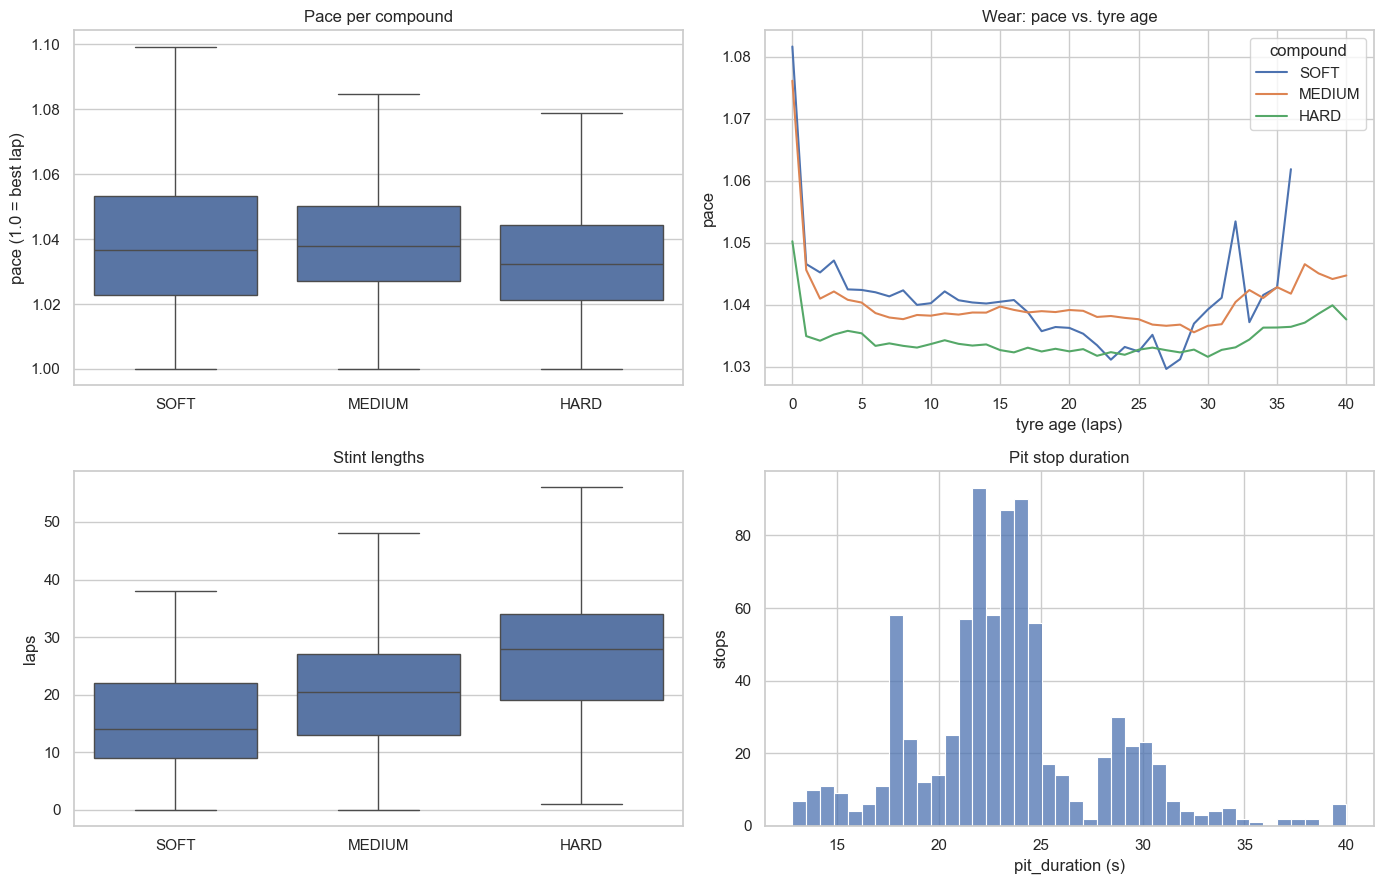

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=laps[laps.compound.isin(COMPOUNDS)], x="compound", y="pace",
            order=COMPOUNDS, ax=axes[0, 0], showfliers=False)
axes[0, 0].set(title="Pace per compound", xlabel="", ylabel="pace (1.0 = best lap)")

sns.lineplot(data=laps[laps.compound.isin(COMPOUNDS) & (laps.age <= 40)],
             x="age", y="pace", hue="compound", hue_order=COMPOUNDS, errorbar=None, ax=axes[0, 1])
axes[0, 1].set(title="Wear: pace vs. tyre age", xlabel="tyre age (laps)", ylabel="pace")

stint_len = stints.assign(n_laps=stints.lap_end - stints.lap_start + 1)
sns.boxplot(data=stint_len[stint_len.compound.isin(COMPOUNDS)], x="compound", y="n_laps",
            order=COMPOUNDS, ax=axes[1, 0], showfliers=False)
axes[1, 0].set(title="Stint lengths", xlabel="", ylabel="laps")

sns.histplot(pit["pit_duration"].clip(upper=40), bins=40, ax=axes[1, 1])
axes[1, 1].set(title="Pit stop duration", xlabel="pit_duration (s)", ylabel="stops")

fig.tight_layout()


## 6. Yellow and Red Flags by Circuit (2023 → Present)

Percentage of race laps affected by a yellow or red flag, circuit by circuit.
For each race: the number of distinct laps during which race control displayed a yellow flag
(`YELLOW` + `DOUBLE YELLOW`, sector or entire track) or a red flag, divided by the race distance; circuits are aggregated across all their races since 2023.

A yellow flag is **not** a neutralization: it can cover a single sector, cost nothing, and be
withdrawn a lap later. The safety car, virtual safety car and red flag laps that sections 7 to 11
actually exclude are built separately, in section 7, and the two measures rank the circuits
differently — Baku is second on this chart and eleventh on the laps genuinely neutralized.

`f1data.load_raw()` fetches the whole period in one pass and caches it: `race_control` and
`session_result` fit within a single range of `session_key`, `laps` goes one request per race.
The reminder now lives in `f1data.key_region()` — OpenF1 only accepts the **strict** operators
`>` and `<` (`session_key>=X` returns a misleading 404).

C:\Users\natha\Documents\formula1-stint-optimizer\app\f1data.py:147: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


91 races held over 2023-2026
  laps          (98184, 16)
  stints        (36955, 8)
  pit           (31783, 8)
  weather       (50929, 10)
  race_control  (26261, 11)
  intervals     (0, 0)
88 races eligible for 91 held since 2023


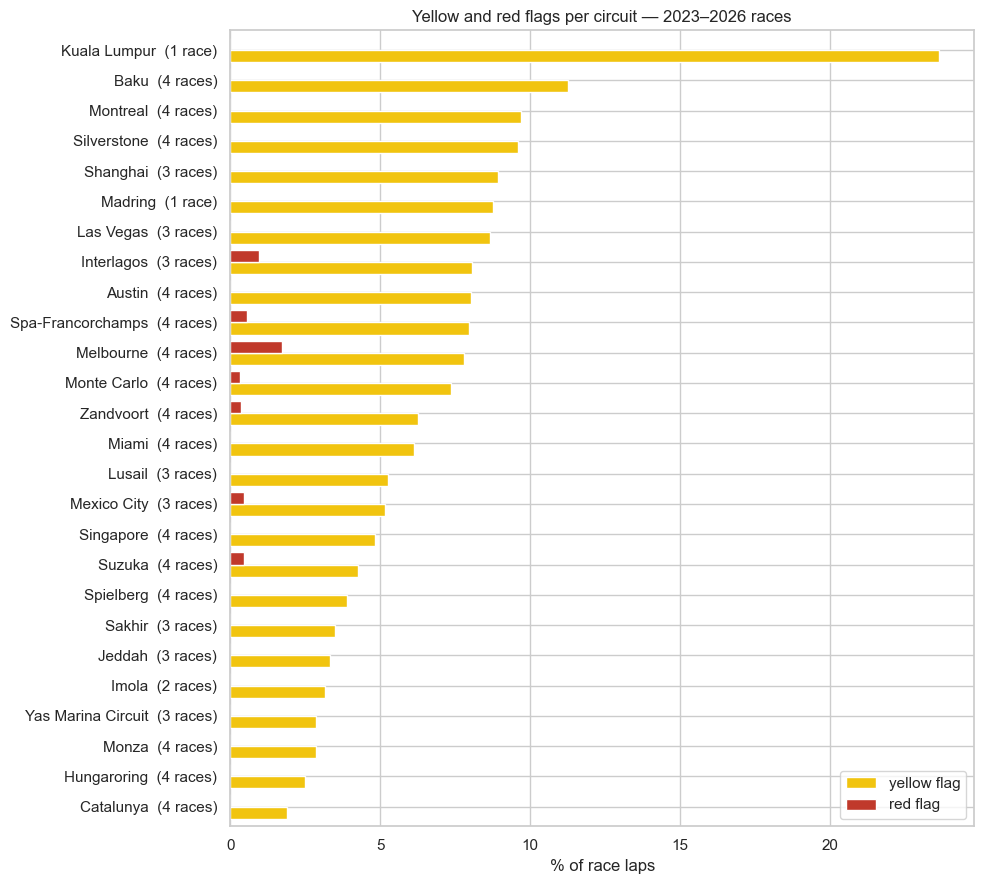

In [60]:
# Every endpoint of the whole 2023-2026 period, cached after the first run. `intervals`
# (traffic) is only needed by the phase 2 baseline, so it stays out of this notebook.
raw = f1data.load_raw(traffic=False)
ses, rc, res, races = raw.sessions, raw.race_control, raw.session_result, raw.races

# We only keep messages sent after the start (before: pit opening, etc.).
events = rc.assign(date=pd.to_datetime(rc["date"], format="ISO8601", utc=True)).merge(
    races[["session_key", "date_start"]], on="session_key")
events = events[events["date"] >= events["date_start"]]

def laps_under(flags):
    return events[events["flag"].isin(flags)].groupby("session_key")["lap_number"].nunique()

flags = races.set_index("session_key")[["circuit_short_name"]].assign(
    laps=res.groupby("session_key")["number_of_laps"].max(),   # distance = lap of the winner
    yellow=laps_under(["YELLOW", "DOUBLE YELLOW"]),
    red=laps_under(["RED"]),
).dropna(subset=["laps"]).fillna(0)

per_circuit = flags.groupby("circuit_short_name").sum()
per_circuit["yellow_%"] = 100 * per_circuit["yellow"] / per_circuit["laps"]
per_circuit["red_%"] = 100 * per_circuit["red"] / per_circuit["laps"]
per_circuit["n"] = flags.groupby("circuit_short_name").size()
print(f"{len(flags)} races eligible for {len(races)} held since 2023")

graph = per_circuit.sort_values("yellow_%").rename(
    columns={"yellow_%": "yellow flag", "red_%": "red flag"})
graph.index = [f"{c}  ({n} race{'s' * (n > 1)})" for c, n in zip(graph.index, graph["n"])]
fig, ax = plt.subplots(figsize=(10, 9))
graph[["yellow flag", "red flag"]].plot.barh(ax=ax, width=0.8, color=["#f1c40f", "#c0392b"])
ax.set(title="Yellow and red flags per circuit — 2023–2026 races",
       xlabel="% of race laps", ylabel="")
ax.legend(loc="lower right")
fig.tight_layout()

## 7. Pit Stop Loss per Lap (2023 → Present)

The true cost of a pit stop is not the time spent in the pit lane, but the time lost compared
to a normal lap: `entry lap + exit lap − 2 × reference lap`. The reference is
taken from the same driver’s clean laps within ±3 laps of the pit stop, which neutralizes the
effect of fuel load, tire wear, and track conditions.

The following are excluded:

- pit stops under **safety car, VSC, or red flag**: the track is slowed down, so the pit stop costs
  much less (here, an average loss of ~86 s without neutralization versus ~25 s with it);
- **races in the rain** (rain detected by `weather`), where the out-lap depends
  primarily on the tire change;
- losses **outside the 10–45 s range**: served penalties, repairs, or botched pit stops—not standard pit stops.

1735 selected pit stops (81 dry races), average loss 22.9 s


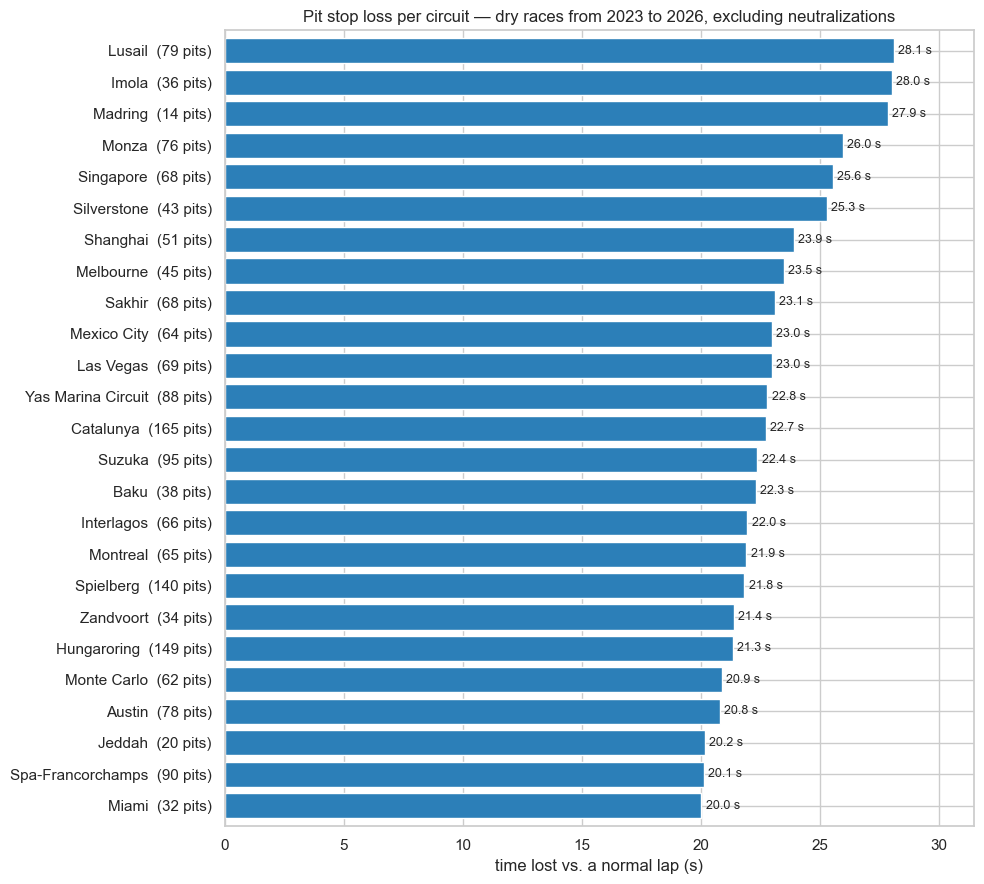

In [61]:
# The loading, the neutralised laps and the lap cleaning all come from f1data: section 9
# builds its table with these very same calls, which is the point of the module.
raw_stops, every_laps = raw.pit, raw.laps
neutral = f1data.neutral_laps(rc)
dry = races[races["session_key"].isin(f1data.dry_keys(raw.weather, races))]
clean = f1data.clean_laps(every_laps, raw_stops)

# A pit stop = its entry lap (lap_number) and its exit lap (lap_number + 1).
lap_time = every_laps.set_index(["session_key", "driver_number", "lap_number"])["lap_duration"]
stops = raw_stops[raw_stops["session_key"].isin(dry["session_key"])][
    ["session_key", "driver_number", "lap_number"]]
stops = stops[[(k, l) not in neutral and (k, l + 1) not in neutral
                 for k, l in zip(stops.session_key, stops.lap_number)]].reset_index(drop=True)
stops["stop_id"] = stops.index
stops["t_in"] = [lap_time.get(i) for i in zip(stops.session_key, stops.driver_number, stops.lap_number)]
stops["t_out"] = [lap_time.get(i) for i in zip(stops.session_key, stops.driver_number, stops.lap_number + 1)]

ref = (stops.merge(clean[["session_key", "driver_number", "lap_number", "lap_duration"]],
                    on=["session_key", "driver_number"], suffixes=("", "_r"))
       .query("abs(lap_number_r - lap_number) <= 3")
       .groupby("stop_id")["lap_duration"].agg(["median", "size"]))
stops = stops.join(ref, on="stop_id")
stops["loss"] = stops["t_in"] + stops["t_out"] - 2 * stops["median"]

selected = stops[(stops["size"] >= 2) & stops["loss"].between(10, 45)].assign(
    circuit=lambda d: d["session_key"].map(races.set_index("session_key")["circuit_short_name"]))
loss = selected.groupby("circuit")["loss"].agg(["mean", "count"]).sort_values("mean")
print(f"{len(selected)} selected pit stops ({len(dry)} dry races), "
      f"average loss {selected['loss'].mean():.1f} s")

fig, ax = plt.subplots(figsize=(10, 9))
loss["mean"].rename(lambda c: f"{c}  ({loss.loc[c, 'count']} pits)").plot.barh(
    ax=ax, width=0.8, color="#2c7fb8")
ax.bar_label(ax.containers[0], fmt="%.1f s", padding=3, fontsize=9)
ax.set(title="Pit stop loss per circuit — dry races from 2023 to 2026, excluding neutralizations",
       xlabel="time lost vs. a normal lap (s)", ylabel="", xlim=(0, loss["mean"].max() * 1.12))
fig.tight_layout()

914 laps | circuits: Austin, Baku, Catalunya, Hungaroring, Imola, Interlagos, Jeddah, Las Vegas, Lusail, Melbourne, Mexico City, Miami, Monte Carlo, Montreal, Monza, Sakhir, Shanghai, Silverstone, Singapore, Spa-Francorchamps, Spielberg, Suzuka, Yas Marina Circuit, Zandvoort


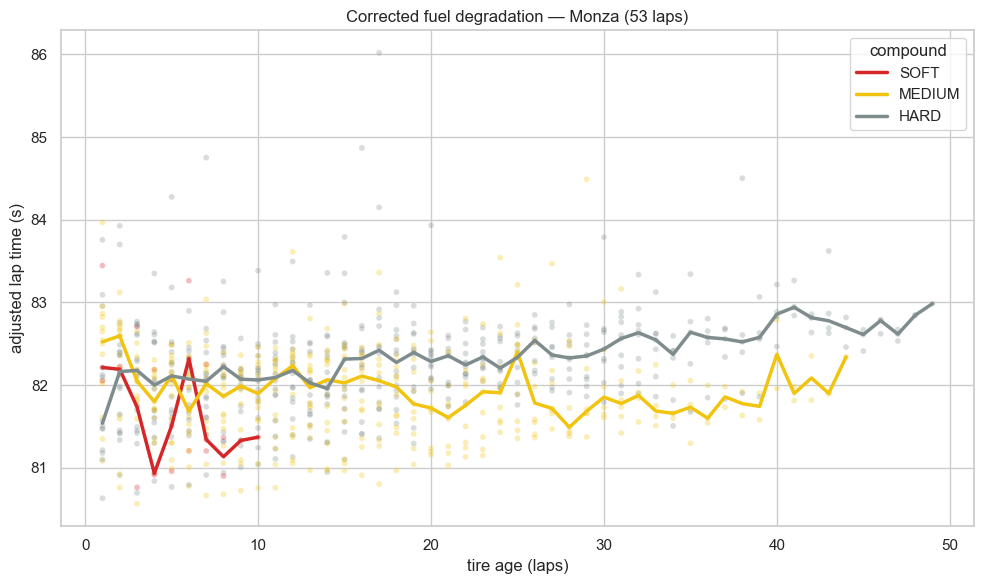

In [62]:
# 8. Fuel degradation corrected, one lap at a time.
# The tank empties by about 1.8 kg per lap, and 10 kg costs ~0.3 s: we remove this
# effect to account only for tire wear. Lap 1 excluded (standing start).
CIRCUIT = "Monza"      # Change the circuit here; the list is printed below the graph
BURN = 0.055           # seconds gained per lap of fuel burned

circuits = sessions_2025.set_index("session_key")["circuit_short_name"]
sel = laps.assign(circuit=laps["session_key"].map(circuits)).query(
    "circuit == @CIRCUIT and lap_number > 1").copy()
distance = sel["lap_number"].max()
sel["adjusted"] = sel["lap_duration"] - BURN * (distance - sel["lap_number"])

compound = [g for g in ["SOFT", "MEDIUM", "HARD"] if (sel["compound"] == g).sum() > 20]
sel = sel[sel["compound"].isin(compound)]
common = dict(data=sel, x="age", y="adjusted", hue="compound", hue_order=compound,
              palette={"SOFT": "#d62728", "MEDIUM": "#f1c40f", "HARD": "#7f8c8d"})

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(**common, ax=ax, alpha=0.3, s=18, legend=False)
sns.lineplot(**common, ax=ax, estimator="median", errorbar=None, lw=2.5)
ax.set(title=f"Corrected fuel degradation — {CIRCUIT} ({distance} laps)",
       xlabel="tire age (laps)", ylabel="adjusted lap time (s)")
fig.tight_layout()
print(f"{len(sel)} laps | circuits: {', '.join(sorted(circuits[laps.session_key.unique()].unique()))}")

## 9. Reference Table by Circuit

The three inputs required by the optimizer, one row per circuit:

- **tire degradation** (s/lap), one slope per circuit, with its dispersion;
- **pit stop loss** (s), taken from Section 7;
- **observed stint lengths** (median and maximum) per tire compound.

Degradation is estimated **per race**, all drivers pooled:
`time = driver pace + compound offset + fuel x lap number + degradation x tire age`.
The "fuel" term accounts for the lighter fuel load **and** track evolution, estimated
from the data rather than being fixed at 0.055 s/lap as in the previous cell—with
that constant, half of the circuits yielded negative tire degradation.

Three modelling choices are worth stating:

- **one slope per circuit, compounds pooled.** The compound keeps an offset, because a new soft
  is not worth a new hard, but it gets no slope of its own: section 11 shows that a slope per
  compound predicts races it has not seen *worse* than a single slope. Only the offset is kept;
  the per-compound columns of the earlier version were not reliable enough to export;
- **fitted per race, not per driver**: inside a single driver's stint, tire age is an affine
  function of the lap number, so with one offset per compound the fuel and degradation terms
  become collinear and the fit has no unique solution. Drivers do not pit on the same laps,
  which is what identifies the two effects. A race keeps only the compounds with at least
  25 clean laps, and at least two of them are required;
- **2026 is held out of training.** Degradation drifts downward season after season (median slope
  0.053 s/lap in 2023, 0.051 in 2024, 0.039 in 2025, 0.025 in 2026): a median over four seasons
  would mix two generations of cars. `slope (s/lap)` and `fuel` are therefore estimated on
  2023-2025 and `slope 2026` is reported beside them, never merged in.

And two rules on what gets published, applied to every fitted parameter:

- **a slope needs 2 training races.** Silverstone has one over 2023-2025 and Madring none, so
  their `slope` and `fuel` cells are empty rather than carrying a number no one can defend;
- **its dispersion needs 3.** `sd (s/lap)` is there for a simulator that draws a slope instead of
  taking a point value, but on two races it is just the distance between two points, which can be
  tiny by luck (Imola and Interlagos came out at 0.002-0.003 s/lap) or huge (Spa at 0.086). Below
  three races the cell carries the calendar-wide value printed under the table, 0.015 s/lap.
  `races` tells which case a row is in.

Stint lengths and pit stop loss are observations rather than fitted parameters, so they stay over
the whole 2023-2026 period and are present even on the two rows that have no slope. One caveat on
them: a median stint length is only the typical length of the stints that *happened*, and when a
compound is used almost exclusively in very short stints the median describes the circumstances,
not the tire — see the Monza soft in section 10.


In [63]:
# The analysis table, built once in f1data and shared with the phase 2 baseline.
# weather rides along for free; traffic is the heavy endpoint and phase 2 asks for it.
base = f1data.build_base(raw, traffic=False)
race_stints = f1data.race_stints(base)

MIN_LAPS = 25     # per compound, below this the compound leaves the race
HOLD_OUT = 2026   # new cars: fitted, but kept out of the exported slope


def fit_race(x):
    """Least squares over one race: a pace level per driver, an offset per compound,
    a fuel slope, and a single degradation slope.

    One slope for the race and not one per compound: section 11 shows that the
    per-compound version predicts held-out races worse. Fitted per race and not per
    driver: inside a single driver's stint, age is an affine function of lap_number,
    so with an offset per compound the fuel and degradation terms become collinear
    (the matrix loses one rank and the solution is arbitrary). Drivers do not pit on
    the same laps, which is what separates the two effects.
    """
    n = x["compound"].value_counts()
    compound = [g for g in n.index if n[g] >= MIN_LAPS]
    x = x[x["compound"].isin(compound)]
    if len(compound) < 2:
        return None
    X = pd.DataFrame(
        {f"pace {d}": (x["driver_number"] == d).astype(float) for d in x["driver_number"].unique()}
        | {f"offset {g}": (x["compound"] == g).astype(float) for g in compound[1:]}
        | {"fuel": x["lap_number"].astype(float), "slope": x["age"].astype(float)})
    coef, _, rank, _ = np.linalg.lstsq(X.values, x["lap_duration"].values, rcond=None)
    if rank < X.shape[1]:        # collinear design: no unique solution
        return None
    return pd.Series(coef, index=X.columns)[["fuel", "slope"]]


# every race returns the same two parameters, so apply gives one row per race,
# indexed by (circuit, session_key).
fits = (base.groupby(["circuit", "session_key"])
        [["driver_number", "lap_number", "age", "compound", "lap_duration"]].apply(fit_race).dropna()
        .join(base.groupby(["circuit", "session_key"])["year"].first()))
train = fits[fits["year"] < HOLD_OUT]

def stint_lengths(f):
    return race_stints.pivot_table(index="circuit", columns="compound", values="n_laps",
                              aggfunc=f).reindex(columns=COMPOUNDS)


# A single race gives no dispersion, and two give the distance between two points,
# which can be tiny by luck. Below MIN_SD races the calendar-wide value is used
# instead, so a simulator drawing from this column is never falsely confident.
MIN_SLOPE = 2     # training races needed to publish a slope
MIN_SD = 3        # training races needed to measure its dispersion

n_races = train.groupby("circuit")["slope"].size()
slope = train.groupby("circuit")["slope"].median().where(n_races >= MIN_SLOPE)
measured = train.groupby("circuit")["slope"].std().where(n_races >= MIN_SD)
FALLBACK = measured.median()

deg = pd.DataFrame({
    "slope (s/lap)": slope.round(3),
    "sd (s/lap)": measured.fillna(FALLBACK).where(slope.notna()).round(3),
    "races": n_races,
    f"slope {HOLD_OUT}": fits[fits["year"] == HOLD_OUT].groupby("circuit")["slope"].median().round(3),
})
deg["races"] = deg["races"].fillna(0).astype(int)

reference = pd.concat({
    "degradation": deg,
    "median stint (laps)": stint_lengths("median").round(0),
    "max stint (laps)": stint_lengths("max"),
    "race": pd.DataFrame({
        "pit stop (s)": loss["mean"].round(1),
        "fuel (s/lap)": train.groupby("circuit")["fuel"].median().where(n_races >= MIN_SLOPE).round(3),
    }),
}, axis=1)
reference.to_csv(f1data.CACHE.parent / "reference_circuits.csv")

print(f"{len(fits)} races fitted, {len(train)} of them in training (before {HOLD_OUT}) | "
      f"median slope per season {fits.groupby('year')['slope'].median().round(3).to_dict()}")
print(f"slope published on {int(deg['slope (s/lap)'].notna().sum())} of {len(deg)} circuits "
      f"(>= {MIN_SLOPE} training races); dispersion measured on {int(measured.notna().sum())} "
      f"of them (>= {MIN_SD} races), the others carry the calendar-wide {FALLBACK:.3f} s/lap")
reference


77 races fitted, 62 of them in training (before 2026) | median slope per season {2023: 0.053, 2024: 0.051, 2025: 0.039, 2026: 0.025}
slope published on 23 of 25 circuits (>= 2 training races); dispersion measured on 15 of them (>= 3 races), the others carry the calendar-wide 0.015 s/lap


degradation                             median stint (laps)              max stint (laps)                      race             
                   slope (s/lap) sd (s/lap) races slope 2026                SOFT MEDIUM  HARD             SOFT MEDIUM  HARD pit stop (s) fuel (s/lap)
circuit                                                                                                                                              
Austin                     0.045      0.021     3        NaN                24.0   21.0  22.0             28.0   34.0  40.0         20.8       -0.069
Baku                       0.034      0.018     3      0.007                15.0   15.0  37.0             31.0   37.0  50.0         22.3       -0.076
Catalunya                  0.071      0.010     3      0.123                14.0   23.0  24.0             32.0   36.0  37.0         22.7       -0.056
Hungaroring                0.060      0.014     3      0.068                14.0   20.0  28.0             34.0   45.0  55.0         21.3       -0.048
Imola                      0.053      0.015     2        NaN                 7.0   19.0  29.0              8.0   37.0  54.0         28.0       -0.042
Interlagos                 0.058      0.015     2        NaN                19.0   25.0  28.0             35.0   52.0  29.0         22.0       -0.035
Jeddah                     0.032      0.019     3        NaN                14.0   17.0  33.0             16.0   41.0  49.0         20.2       -0.061
Las Vegas                  0.033      0.026     3        NaN                 4.0   16.0  23.0             10.0   27.0  48.0         23.0       -0.088
Lusail                     0.034      0.025     3        NaN                 7.0   18.0  18.0             25.0   35.0  30.0         28.1       -0.081
Madring                      NaN        NaN     0      0.011                11.0   14.0  39.0             23.0   20.0  55.0         27.9          NaN
Melbourne                  0.024      0.015     2      0.038                10.0    9.0  25.0             25.0   38.0  48.0         23.5       -0.051
Mexico City                0.048      0.008     3        NaN                24.0   28.0  37.0             37.0   44.0  49.0         23.0       -0.045
Miami                      0.028      0.004     3      0.017                15.0   24.0  31.0             29.0   41.0  54.0         20.0       -0.056
Monte Carlo                0.029      0.015     2      0.022                11.0   30.0  31.0             55.0   78.0  78.0         20.9       -0.061
Montreal                   0.024      0.015     2     -0.018                17.0   16.0  31.0             38.0   49.0  68.0         21.9       -0.041
Monza                      0.046      0.025     3      0.014                 3.0   19.0  25.0             24.0   50.0  51.0         26.0       -0.061
Sakhir                     0.121      0.015     3        NaN                13.0   19.0  20.0             25.0   31.0  30.0         23.1       -0.071
Shanghai                   0.075      0.015     2      0.025                 9.0   12.0  33.0             20.0   30.0  47.0         23.9       -0.078
Silverstone                  NaN        NaN     1      0.058                19.0   24.0  20.0             28.0   35.0  34.0         25.3          NaN
Singapore                  0.043      0.012     3      0.025                22.0   25.0  34.0             61.0   60.0  49.0         25.6       -0.047
Spa-Francorchamps          0.121      0.015     2      0.052                12.0   15.0  21.0             27.0   24.0  34.0         20.1       -0.097
Spielberg                  0.062      0.007     3      0.070                13.0   20.0  27.0             25.0   33.0  41.0         21.8       -0.030
Suzuka                     0.115      0.046     3      0.032                11.0   20.0  23.0             20.0   33.0  38.0         22.4       -0.077
Yas Marina Circuit         0.058      0.005     3        NaN                 8.0   16.0  25.0             25.0   29.0  45

## 10. Three Race Profiles

The three entries in Section 9 (tire degradation, pit stop time loss, stint lengths) reviewed
track by track, across three deliberately contrasting races:

| track | reason | details |
|---|---|---|
| **Monza** | the costly stop: 26.0 s, 4th on the calendar, and a one-stop race — although its wear is mid-pack, 0.046 s/lap, 12th of the 23 published slopes | 76 pit stops, 180 stints |
| **Catalunya** | the abrasive one: 0.071 s/lap, 5th on the calendar, three training races and the tightest dispersion of the table (0.010 s/lap), on the largest sample. Two stops | 165 pit stops, 265 stints |
| **Baku** | the flat one, 0.034 s/lap, and the one that flies the most yellows — **11.3%** of its race laps since 2023, the highest on the calendar outside of Kuala Lumpur (a single race). Yellows, not neutralizations: on safety-car and red-flag laps Baku is only 11th | 38 pit stops, 154 stints |

The contrast is therefore three different reasons to stop once or twice, not three levels of wear:
an expensive stop, an abrasive surface, and a track where the race is interrupted often.

Read by column:

- **degradation** — each point represents a clean lap; the line is the moving median by tire age.
  The panel title carries the circuit's single slope from Section 9; the three curves are labelled
  by compound but share that one slope, and section 11 explains why no slope per compound is
  published. Laps are expressed as
  **deviation from the median lap time of their own race**: 2023 and 2026 have neither the same cars nor
  the same track surface, and without this normalization, we would be measuring the evolution of the field rather than
  tire wear. The effect of fuel is accounted for using the estimated slope for the circuit;
- **pit stop loss** — distribution of pit stops, circuit average shown as a solid line, average across all
  circuits shown as a dashed line;
- **stint lengths** — distribution by tire compound, one point per stint.

The three columns share the same scale from one row to the next: the rows can be compared
directly. Same race layout as Section 9—dry races only, excluding neutralized laps.

> **Monza soft, a warning on reading stint lengths.** Its median of 3 laps rests on 17 stints,
> and they are not racing stints: 7 of them are drivers who started on the soft in 2026 and pitted
> on lap 3 together, 5 more are end-of-race runs started after 87 % of the distance, and each of
> those contributes a single clean lap. Only 3 of the 17 last more than 10 laps. Across the
> calendar 4.0 % of soft stints are 3 laps or shorter, against 0.8 % for the medium and 0.4 % for
> the hard, and Monza soft is the only circuit x compound cell with at least 10 stints whose median
> is under 5 laps. The number is real; what it describes is the circumstances of those stints, not
> the life of a soft tire at Monza.

> Colors: red, yellow, and gray are the F1 tire codes. Yellow remains clearly visible against a
> white background, so each curve also has its own label and each box has its median value:
> identification is never based on color alone.

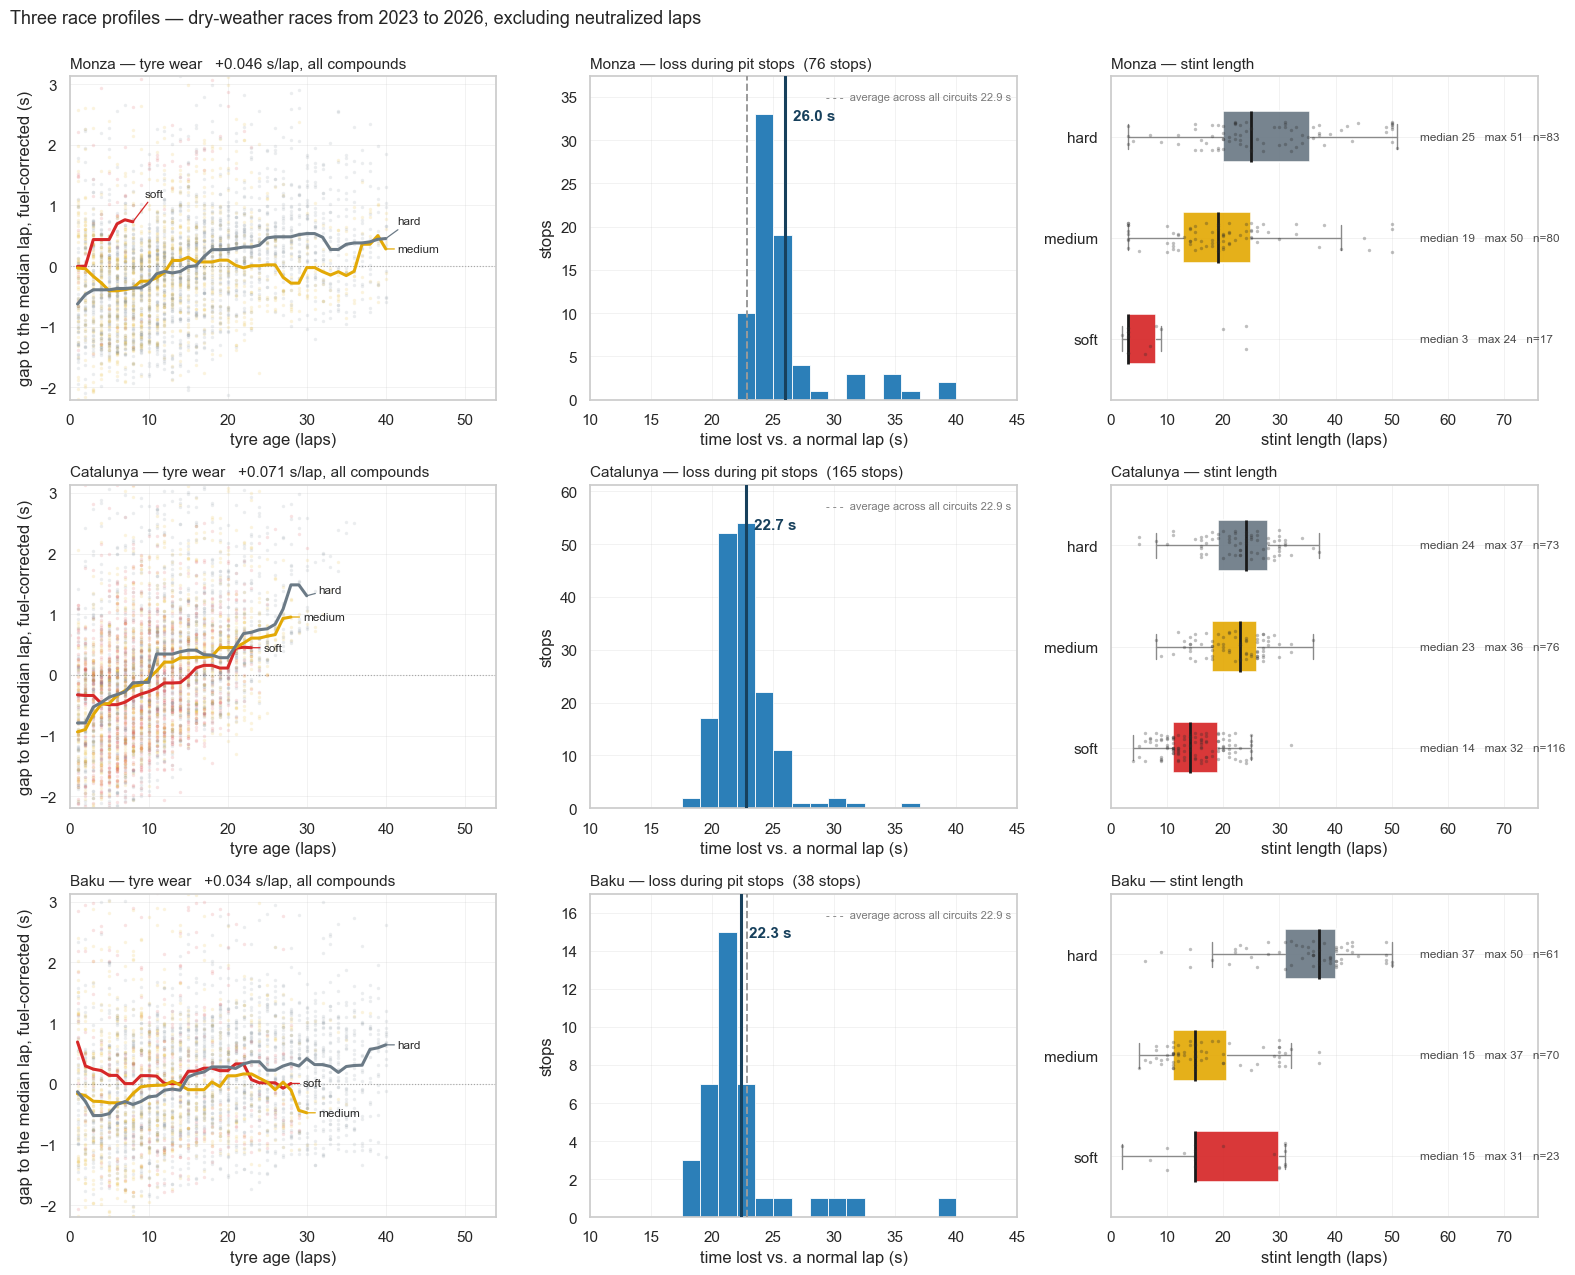

In [64]:
THREE = ["Monza", "Catalunya", "Baku"]
TYRE_COLOR = {"SOFT": "#d62728", "MEDIUM": "#e3a906", "HARD": "#6b7a86"}
MAX_AGE = 40

# times adjusted to the median lap time of THEIR race (performance levels vary
# from one season to the next), then corrected with the circuit's fuel slope.
fuel = fits.groupby("circuit")["fuel"].median()
cloud = base[base["circuit"].isin(THREE) & (base["age"] <= MAX_AGE)].copy()
by_race = cloud.groupby("session_key")
cloud["gap"] = (cloud["lap_duration"] - by_race["lap_duration"].transform("median")
                  - cloud["circuit"].map(fuel)
                  * (cloud["lap_number"] - by_race["lap_number"].transform("median")))

ylim = tuple(np.percentile(cloud["gap"], [2, 98]) * 1.15)
max_stint = race_stints[race_stints["circuit"].isin(THREE)]["n_laps"].max()
global_loss = selected["loss"].mean()


def no_overlap(ys, min_gap):
    """Spaces out labels that are too close together vertically, while maintaining their order."""
    order = np.argsort(ys)
    levels = np.array(ys, dtype=float)[order]
    for i in range(1, len(levels)):
        levels[i] = max(levels[i], levels[i - 1] + min_gap)
    output = np.empty_like(levels)
    output[order] = levels
    return output


fig, axes = plt.subplots(3, 3, figsize=(16, 13))
rng = np.random.default_rng(0)

for line, circuit in enumerate(THREE):
    laps_c = cloud[cloud["circuit"] == circuit]

    # --- degradation: lap cloud + moving median by tire -------------------
    ax = axes[line, 0]
    ends = []
    for comp in [g for g in COMPOUNDS if (laps_c["compound"] == g).sum() > 50]:
        pts = laps_c[laps_c["compound"] == comp]
        ax.scatter(pts["age"], pts["gap"], s=6, alpha=0.13, color=TYRE_COLOR[comp], lw=0, zorder=1)
        med = pts.groupby("age")["gap"].agg(["median", "size"])
        med = med[med["size"] >= 5]["median"].rolling(3, center=True, min_periods=1).median()
        ax.plot(med.index, med.values, color=TYRE_COLOR[comp], lw=2.2, zorder=3, solid_capstyle="round")
        ends.append((med.values[-1], med.index[-1], TYRE_COLOR[comp], comp.lower()))
    for y, (y0, x0, color, text) in zip(
            no_overlap([f[0] for f in ends], 0.085 * (ylim[1] - ylim[0])), ends):
        ax.annotate(text, (x0, y0), xytext=(x0 + 1.5, y), fontsize=8.5, va="center",
                    color="#2b2b2b", zorder=4,
                    arrowprops=dict(arrowstyle="-", color=color, lw=0.9, shrinkA=0, shrinkB=1))
    ax.axhline(0, color="#9a9a9a", lw=0.8, ls=":", zorder=0)
    ax.set(xlim=(0, MAX_AGE + 14), ylim=ylim, xlabel="tyre age (laps)",
           ylabel="gap to the median lap, fuel-corrected (s)")
    pente = deg.loc[circuit, "slope (s/lap)"]
    ax.set_title(f"{circuit} — tyre wear" + (f"   {pente:+.3f} s/lap, all compounds"
                 if pd.notna(pente) else ""), loc="left", fontsize=11)

    # --- pit stop loss ---------------------------------------------------------------
    ax = axes[line, 1]
    p = selected.loc[selected["circuit"] == circuit, "loss"]
    ax.hist(p, bins=np.arange(10, 46, 1.5), color="#2c7fb8", edgecolor="white", lw=0.6, zorder=2)
    top = ax.get_ylim()[1]
    ax.axvline(global_loss, color="#9a9a9a", lw=1.4, ls="--", zorder=3)
    ax.axvline(p.mean(), color="#17405c", lw=2.2, zorder=4)
    ax.annotate(f"{p.mean():.1f} s", (p.mean(), top * 0.97), xytext=(6, 0),
                textcoords="offset points", fontsize=11, fontweight="bold",
                color="#17405c", va="top", zorder=5)
    ax.annotate(f"- - -  average across all circuits {global_loss:.1f} s", (0.985, 0.95),
                xycoords="axes fraction", ha="right", va="top", fontsize=8, color="#7a7a7a")
    ax.set(xlim=(10, 45), ylim=(0, top * 1.08),
           xlabel="time lost vs. a normal lap (s)", ylabel="stops")
    ax.set_title(f"{circuit} — loss during pit stops  ({len(p)} stops)", loc="left", fontsize=11)

    # --- stint length ------------------------------------------------------------
    ax = axes[line, 2]
    r = race_stints[race_stints["circuit"] == circuit]
    present = [g for g in COMPOUNDS if (r["compound"] == g).sum() >= 5]
    for i, comp in enumerate(present):
        n = r.loc[r["compound"] == comp, "n_laps"]
        ax.boxplot([n], positions=[i], vert=False, widths=0.5, showfliers=False,
                   patch_artist=True, medianprops=dict(color="#1a1a1a", lw=2),
                   boxprops=dict(facecolor=TYRE_COLOR[comp], edgecolor="white", lw=1.2, alpha=0.92),
                   whiskerprops=dict(color="#8a8a8a"), capprops=dict(color="#8a8a8a"))
        ax.scatter(n, i + rng.uniform(-0.15, 0.15, len(n)), s=6, color="#2b2b2b",
                   alpha=0.3, lw=0, zorder=3)
        ax.annotate(f"median {n.median():.0f}   max {n.max():.0f}   n={len(n)}",
                    (max_stint + 4, i), ha="left", va="center", fontsize=8.5, color="#4a4a4a")
    ax.set(yticks=range(len(present)), yticklabels=[g.lower() for g in present],
           xlim=(0, max_stint + 25), ylim=(-0.6, len(present) - 0.4),
           xlabel="stint length (laps)")
    ax.set_title(f"{circuit} — stint length", loc="left", fontsize=11)

for ax in axes.flat:
    ax.grid(alpha=0.3, lw=0.6)
    ax.set_axisbelow(True)

fig.suptitle("Three race profiles — dry-weather races from 2023 to 2026, excluding neutralized laps",
             fontsize=13, x=0.006, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.985))

## 11. Are the Slopes per Compound Usable?

Section 9 exports a single slope per circuit. A slope per compound looks like the obvious
refinement — a soft does wear faster than a hard — and the earlier version of the table did
export one, but the compounds would not come out in the expected order: on the 15 circuits where
the three are measured, the soft is the steepest on 9 and the hard on 3, and only 6 are ordered
soft > medium > hard. Four checks, from the weakest to the most decisive, say whether that
ordering is recoverable at all.

1. **The offsets first.** The prior on them is far stronger than on the slopes: a new hard tyre has
   to be slower than a new medium, itself slower than a new soft. Offsets that are not ordered mean
   the problem is not confined to the slopes.
2. **The real uncertainty**: one estimate per race, with its standard error, rather than a median
   that hides its own spread.
3. **The same age window** for every compound (<= 15 laps), since the soft is almost never run old:
   the compounds are otherwise compared over different parts of the curve.
4. **Prediction**, which settles it. Each race is held out in turn, the model is fitted on the other
   races of the same circuit, and the lap times of the held-out race are predicted. Every driver of
   that race keeps a free pace level, so only the tyre and fuel structure is being scored. Three
   nested models are compared: no tyre term, one slope per circuit, one slope per compound.

The first two panels share the same circuit order (increasing degradation).


0. per-compound: on 15 circuits with the three compounds, expected order on 6, soft steepest on 9, hard steepest on 3 (72 races where the hard is measured)
1. offsets    : soft faster than hard on 23/37 races, medium on 15/37; expected order on 6/21 circuits
2. dispersion : sd between races of one circuit+compound 0.022 s/lap, against 0.030 between compounds; standard error inside a race 0.005
3. age <= 15  : expected order on 5/20 circuits, against 6/15 without the age window
4. prediction : 76 held-out races, a slope per compound wins on 34/76; the tyre terms beat 'no tyre' on 65/76


,all,age <= 10,11-20,21-30,age > 30
model,,,,,
no tyre,0.771,0.810,0.674,0.767,0.948
one slope,0.703,0.725,0.624,0.696,0.894
slope/compound,0.710,0.730,0.632,0.704,0.902


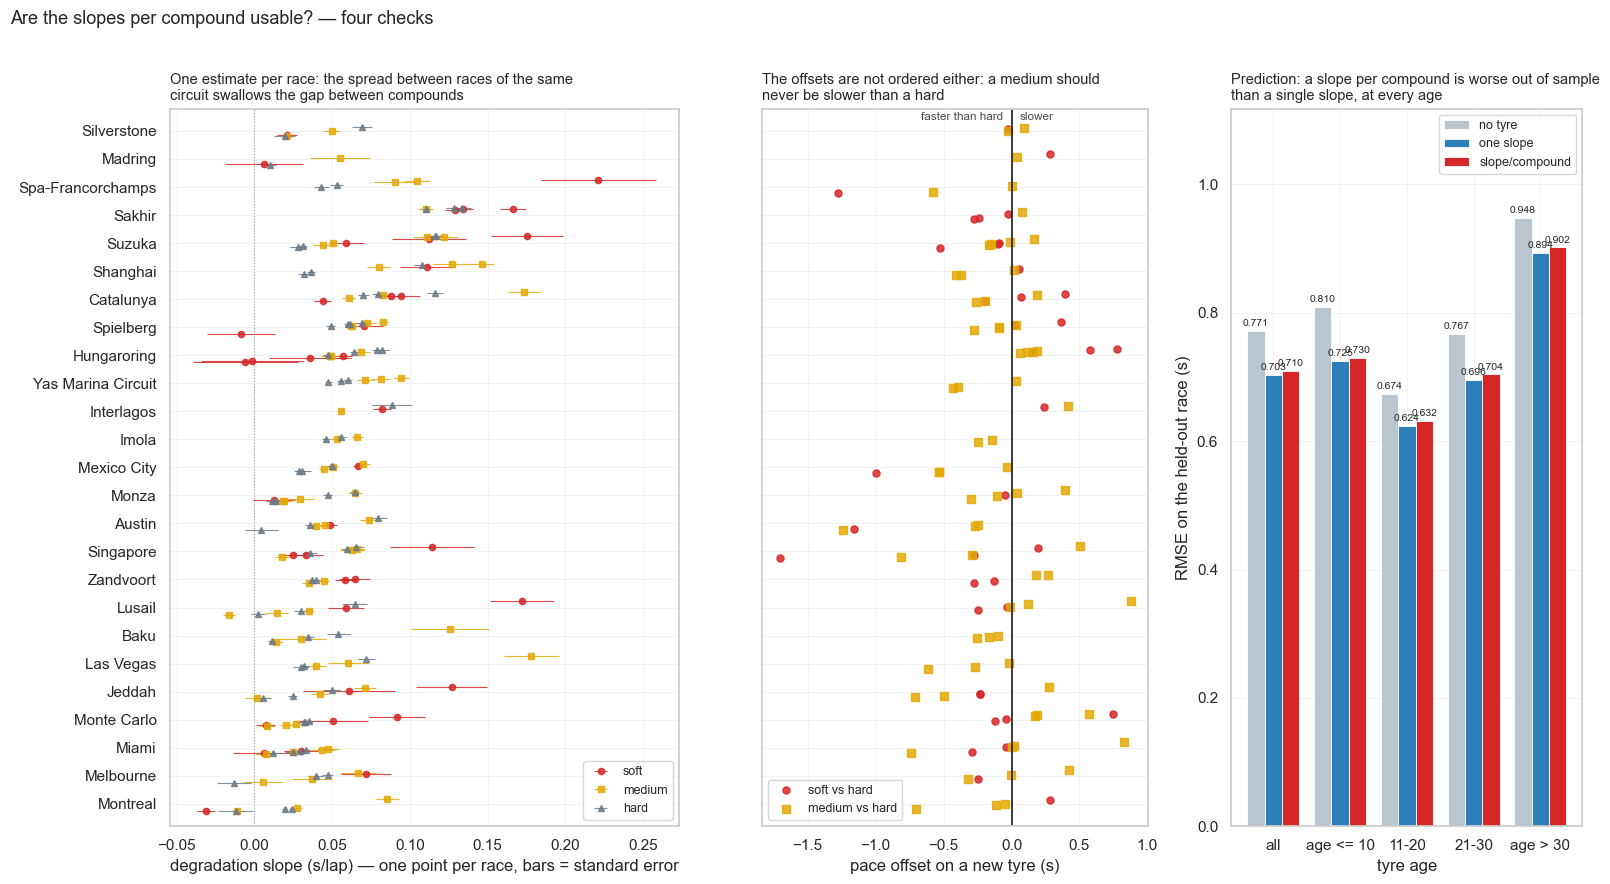

In [65]:
REF = "HARD"          # reference compound: the offsets are read against it
WINDOW = 15           # common age windowed (lap_test 3)


def estimate(x, max_age=None):
    """Same model as section 9, but returns the offsets and the standard errors."""
    if max_age is not None:
        x = x[x["age"] <= max_age]
    n = x["compound"].value_counts()
    comp = [g for g in COMPOUNDS if n.get(g, 0) >= MIN_LAPS]
    if REF not in comp or len(comp) < 2:
        return None
    x = x[x["compound"].isin(comp)]
    X = pd.DataFrame(
        {f"pace|{d}": (x["driver_number"] == d).astype(float) for d in x["driver_number"].unique()}
        | {f"offset|{g}": (x["compound"] == g).astype(float) for g in comp if g != REF}
        | {"fuel": x["lap_number"].astype(float)}
        | {f"slope|{g}": x["age"].where(x["compound"] == g, 0.0) for g in comp})
    coef, _, rank, _ = np.linalg.lstsq(X.values, x["lap_duration"].values, rcond=None)
    if rank < X.shape[1]:
        return None
    r = x["lap_duration"].values - X.values @ coef
    se = np.sqrt(np.diag(np.linalg.inv(X.values.T @ X.values)) * (r @ r) / (len(r) - X.shape[1]))
    out = pd.DataFrame({"value": coef, "se": se}, index=X.columns)
    return out[~out.index.str.startswith("pace|")]


def per_race(max_age=None):
    rows = []
    for (c, s), x in base.groupby(["circuit", "session_key"]):
        e = estimate(x, max_age)
        if e is None:
            continue
        rows.append(e.assign(circuit=c, session_key=s, kind=e.index.str.split("|").str[0],
                             compound=e.index.str.split("|").str[1]))
    return pd.concat(rows, ignore_index=True)


est = per_race()
slopes = est[est["kind"] == "slope"]
offsets = est[est["kind"] == "offset"]


# --- lap_test 4: predict races that were held out, three nested models --------------
def columns(x, comp, mode):
    cols = {"fuel": x["lap_number"].astype(float)}
    cols |= {f"off|{g}": (x["compound"] == g).astype(float) for g in comp[1:]}
    if mode == "one slope":
        cols |= {"age": x["age"].astype(float)}
    elif mode == "slope/compound":
        cols |= {f"age|{g}": x["age"].where(x["compound"] == g, 0.0) for g in comp}
    return pd.DataFrame(cols, index=x.index)


MODES = ["no tyre", "one slope", "slope/compound"]
scores = []
for circuit, grp in base.groupby("circuit"):
    courses = sorted(grp["session_key"].unique())
    if len(courses) < 2:        # a circuit with a single race cannot be held out
        continue
    for held in courses:
        lap_train, lap_test = grp[grp.session_key != held], grp[grp.session_key == held]
        comp = [g for g in COMPOUNDS if (lap_train["compound"] == g).sum() >= MIN_LAPS]
        lap_train, lap_test = lap_train[lap_train["compound"].isin(comp)], lap_test[lap_test["compound"].isin(comp)]
        if len(lap_test) < 50:
            continue
        crew = pd.get_dummies(lap_train["session_key"].astype(str) + lap_train["driver_number"].astype(str)).astype(float)
        for mode in MODES:
            D = columns(lap_train, comp, mode)
            A = pd.concat([crew, D], axis=1)
            coef, _, rank, _ = np.linalg.lstsq(A.values, lap_train["lap_duration"].values, rcond=None)
            if rank < A.shape[1]:
                continue
            beta = pd.Series(coef, index=A.columns)[D.columns]
            r = lap_test["lap_duration"].values - columns(lap_test, comp, mode).values @ beta.values
            # every driver of the held-out race keeps a free pace level: only the
            # tyre and fuel structure is being scored.
            r = r - pd.Series(r, index=lap_test.index).groupby(lap_test["driver_number"]).transform("mean").values
            scores.append(pd.DataFrame({"circuit": circuit, "race": held, "model": mode,
                                        "res": r, "age": lap_test["age"].values}))
scores = pd.concat(scores, ignore_index=True)


def rms(s):
    return np.sqrt((s ** 2).mean())


brackets = {"all": scores.age > -1, "age <= 10": scores.age <= 10, "11-20": scores.age.between(11, 20),
            "21-30": scores.age.between(21, 30), "age > 30": scores.age > 30}
rmse = pd.DataFrame({k: scores[m].groupby("model")["res"].apply(rms)
                     for k, m in brackets.items()}).reindex(MODES)
race_rmse = scores.pivot_table(index="race", columns="model", values="res", aggfunc=rms).dropna()

# --- figure ---------------------------------------------------------------------
MARK = {"SOFT": "o", "MEDIUM": "s", "HARD": "^"}
order = list(deg["slope (s/lap)"].sort_values().index)
rank = {c: i for i, c in enumerate(order)}


def spread(v, width):
    """Vertical spacing, so that the points of one circuit do not overlap."""
    return np.linspace(-width, width, len(v))[np.argsort(np.argsort(v))]


fig, axes = plt.subplots(1, 3, figsize=(16, 9), gridspec_kw={"width_ratios": [1.45, 1.1, 1]})

ax = axes[0]
for comp in COMPOUNDS:
    s = slopes[slopes["compound"] == comp]
    ax.errorbar(s["value"], [rank[c] for c in s["circuit"]] + spread(s["value"].values, 0.26),
                xerr=s["se"], fmt=MARK[comp], ms=4.5, lw=0, elinewidth=0.8, color=TYRE_COLOR[comp],
                ecolor=TYRE_COLOR[comp], alpha=0.85, label=comp.lower())
ax.axvline(0, color="#9a9a9a", lw=0.8, ls=":")
ax.set(yticks=range(len(order)), yticklabels=order, ylim=(-0.8, len(order) - 0.2),
       xlabel="degradation slope (s/lap) — one point per race, bars = standard error")
ax.set_title("One estimate per race: the spread between races of the same\n"
             "circuit swallows the gap between compounds", loc="left", fontsize=10.5)
ax.legend(loc="lower right", fontsize=9)

ax = axes[1]
for comp in ["SOFT", "MEDIUM"]:
    o = offsets[offsets["compound"] == comp]
    ax.scatter(o["value"], [rank[c] for c in o["circuit"]] + spread(o["value"].values, 0.22),
               marker=MARK[comp], s=26, color=TYRE_COLOR[comp], alpha=0.85, label=f"{comp.lower()} vs hard")
ax.axvline(0, color="#1a1a1a", lw=1.2)
ax.annotate("faster than hard", (-0.06, len(order) - 0.6), ha="right", fontsize=8.5, color="#4a4a4a")
ax.annotate("slower", (0.06, len(order) - 0.6), ha="left", fontsize=8.5, color="#4a4a4a")
ax.set(yticks=range(len(order)), yticklabels=[], ylim=(-0.8, len(order) - 0.2),
       xlabel="pace offset on a new tyre (s)")
ax.set_title("The offsets are not ordered either: a medium should\n"
             "never be slower than a hard", loc="left", fontsize=10.5)
ax.legend(loc="lower left", fontsize=9)

ax = axes[2]
width, xs = 0.26, np.arange(len(rmse.columns))
for i, m in enumerate(MODES):
    bars = ax.bar(xs + (i - 1) * width, rmse.loc[m], width, label=m,
                  color=["#b9c6cf", "#2c7fb8", "#d62728"][i], edgecolor="white", lw=0.6)
    ax.bar_label(bars, fmt="%.3f", fontsize=7.5, padding=2)
ax.set(xticks=xs, xticklabels=rmse.columns, ylim=(0, rmse.values.max() * 1.18),
       ylabel="RMSE on the held-out race (s)", xlabel="tyre age")
ax.set_title("Prediction: a slope per compound is worse out of sample\n"
             "than a single slope, at every age", loc="left", fontsize=10.5)
ax.legend(fontsize=9)

for a in axes:
    a.grid(alpha=0.3, lw=0.6)
    a.set_axisbelow(True)
fig.suptitle("Are the slopes per compound usable? — four checks", fontsize=13, x=0.006, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))

# --- verdict ---------------------------------------------------------------------
pair = offsets.pivot_table(index=["circuit", "session_key"], columns="compound", values="value").dropna()
med_off = offsets.groupby(["circuit", "compound"])["value"].median().unstack().dropna()
windowed = per_race(WINDOW)
w = (windowed[windowed["kind"] == "slope"]
     .pivot_table(index="circuit", columns="compound", values="value", aggfunc="median")
     .reindex(columns=COMPOUNDS).dropna())
# the per-compound slopes, which section 9 no longer exports: rebuilt here to be judged,
# with the same 10-stint floor as the earlier version of the table.
by_compound = (slopes.pivot_table(index="circuit", columns="compound", values="value", aggfunc="median")
             .reindex(columns=COMPOUNDS))
d3 = by_compound.where(stint_lengths("size").reindex(index=by_compound.index, columns=COMPOUNDS).fillna(0) >= 10).dropna()
between = slopes.groupby(["circuit", "compound"])["value"].agg(["std", "size"])

print(f"0. per-compound: on {len(d3)} circuits with the three compounds, expected order on "
      f"{((d3.SOFT > d3.MEDIUM) & (d3.MEDIUM > d3.HARD)).sum()}, soft steepest on "
      f"{(d3.SOFT == d3.max(axis=1)).sum()}, hard steepest on {(d3.HARD == d3.max(axis=1)).sum()}"
      f" ({est.session_key.nunique()} races where the hard is measured)")
print(f"1. offsets    : soft faster than hard on {(pair.SOFT < 0).sum()}/{len(pair)} races, "
      f"medium on {(pair.MEDIUM < 0).sum()}/{len(pair)}; expected order on "
      f"{((med_off.SOFT < med_off.MEDIUM) & (med_off.MEDIUM < 0)).sum()}/{len(med_off)} circuits")
print(f"2. dispersion : sd between races of one circuit+compound "
      f"{between[between['size'] >= 2]['std'].median():.3f} s/lap, against "
      f"{(d3.max(axis=1) - d3.min(axis=1)).median():.3f} between compounds; "
      f"standard error inside a race {slopes['se'].median():.3f}")
print(f"3. age <= {WINDOW}  : expected order on "
      f"{((w.SOFT > w.MEDIUM) & (w.MEDIUM > w.HARD)).sum()}/{len(w)} circuits, against "
      f"{((d3.SOFT > d3.MEDIUM) & (d3.MEDIUM > d3.HARD)).sum()}/{len(d3)} without the age window")
print(f"4. prediction : {len(race_rmse)} held-out races, a slope per compound wins on "
      f"{(race_rmse['slope/compound'] < race_rmse['one slope']).sum()}/{len(race_rmse)}; "
      f"the tyre terms beat 'no tyre' on "
      f"{(race_rmse['one slope'] < race_rmse['no tyre']).sum()}/{len(race_rmse)}")
rmse.round(3)


## Findings from the Analysis (Phase 1)

**Scope**: 91 races held since 2023, of which 81 dry; 77 have enough clean laps to be fitted, and
62 of those are in the training window (2023-2025, 2026 held apart). 3 756 stints and 1 735
measured pit stops. Neutralized laps excluded throughout.

### Findings

- **Degradation is first and foremost a circuit effect.** The published slopes run from
  0.024 s/lap (Melbourne, Montreal) to 0.121 (Sakhir), with a flat group (Melbourne and Montreal
  0.024, Miami 0.028, Monte Carlo 0.029) and an abrasive one (Catalunya 0.071, Suzuka 0.115,
  Sakhir 0.121, all three on three training races). Spa also comes out at 0.121 and Shanghai at
  0.075, but on two races each, with no reliable central value — provisional, not calendar facts.
  The circuit is a mandatory variable, and the tyre term earns its place: it lowers the held-out
  error from 0.771 s to 0.703 s per lap, and wins on 65 races out of 76.
- **The compound is not usable, neither its slope nor its offset** (section 11), which is why the
  table exports one slope per circuit instead of three. The offsets fail first: the medium comes
  out *slower* than the hard on 22 races out of 37, and the expected order holds on only 6 circuits
  out of 21 — against a prior that admits no exception. The slope per compound then loses the
  arbitration: out of sample it is worse than a single slope per circuit (0.710 vs 0.703 s overall,
  and worse in every age bracket, 0.730 vs 0.725 below 10 laps, 0.902 vs 0.894 beyond 30) and it
  only wins on 34 races out of 76. Restricting every compound to the same window (<= 15 laps)
  changes nothing: 5 circuits out of 20 in order. **A slope per compound is noise being fitted.**
- **The uncertainty is between races, not inside a race.** Where it can be measured — three
  training races — the dispersion of a circuit's slopes runs from 0.004 s/lap (Miami) to 0.046
  (Suzuka), median 0.015, on central values of 0.02 to 0.12. The standard error computed inside a
  single race, 0.005 s/lap, understates it: something that changes from race to race (temperature,
  tyre allocation, curvature of track evolution) is missing from the model. Two races say nothing
  about it — the same column gave 0.002 at Interlagos and 0.086 at Spa — so below three races the
  table carries the calendar-wide value instead, and a slope itself is published only from two.
- **The seasons drift**: median slope of 0.053 s/lap in 2023, 0.051 in 2024, 0.039 in 2025 and
  0.025 in 2026, i.e. halved in four seasons. 2026 is therefore kept out of training and reported
  in its own column: it comes out below the training value on 9 of the 14 circuits that have a
  2026 race (median gap -0.014). Catalunya is the loud exception, 0.123 against 0.071, on a single
  race.
- **Pit stop loss is not a constant**: an average of 22.9 s, but from 20.0 s (Miami) to 28.1 s
  (Lusail), a standard deviation of 2.4 s across circuits. That 8 s spread is larger than all the
  wear accumulated over a median stint. The tail matters too: 7.3 % of stops exceed 30 s, the 99th
  percentile is 40 s. It drifts in 2026 as well (24.5 s against 22.4 to 22.8 in 2023-2025), and
  unlike the slope the exported column still averages the four seasons.
- **What wear costs over a stint is small**: slope x median stint length gives roughly 0.5 to 2.5 s
  depending on the circuit and the compound — about 1 s at Monza, 2.4 s at Sakhir — against
  20-28 s for a stop. Strategy is driven by the arithmetic of the stop over the whole race, not by
  what a single stint loses.
- **Fuel burn is worth estimating**: the fitted slope goes from -0.030 s/lap (Spielberg) to
  -0.097 (Spa), median around -0.057, negative on all 23 circuits that publish one. The fixed
  0.055 of section 8 lands on the median but is off by nearly a factor of 2 at both extremes.
- **A median stint length is not a tyre property.** Monza soft reads 3 laps over 17 stints, and
  those stints are 7 lap-3 pit stops on a single 2026 afternoon plus 5 end-of-race runs, each
  contributing one clean lap. The figure is right and the reading would be wrong: it describes
  when the compound was used, not how long it lasts. Across the calendar 4.0 % of soft stints are
  3 laps or shorter, against 0.4 % for the hard.

### Consistency Test: Number of Stops

With equal stints, the exported slope and the measured pit loss, the cost of `k` stops is
`k x pit + slope x L x (L / (k + 1) - 1) / 2` for a race of `L` laps. Taking the minimum over `k`,
with at least one stop (the two-compound rule), this **matches the observed median on 19 of the
23 circuits** that publish a slope — including the hypothesis stated before the analysis: one stop
at Monza and Baku, two at Catalunya.

The four misses: Zandvoort and Spa (margins of 4.1 s and 0.6 s between one and two stops, inside
the race-to-race dispersion), Suzuka (two predicted, one observed, 4.5 s margin), and Lusail, the
only real one: one stop predicted against a 19 s margin, two observed, with stints capped around
18 laps. That cap does not come from pace and has to be looked for elsewhere (a tyre-life limit
imposed on that race is the hypothesis).

### What This Model Cannot Do

It predicts how a lap time decays with tyre age on a given circuit. It **cannot choose a compound**:
that arbitration needs the pace offset between compounds and the difference between their slopes
(the crossover age is one divided by the other), and neither of the two is identified here. The
likely cause is a confound rather than a lack of data: which compound is on the car is tied to when
it runs, so a compound effect and a race-phase effect cannot be told apart by a model whose only
time variable is a straight line in lap number.

### To Be Verified Before Modeling

- [ ] **The compound confound**, which is the blocking item: add what varies with the race phase
      (track and air temperature, laps since the last neutralization) and check whether the offsets
      come back into order. As long as they do not, compound choice stays outside the simulator.
- [ ] **Thin circuits**: Madring has no training race at all (2026 only) and Silverstone only one,
      so neither publishes a slope. Either accept two blank rows or move to a hierarchical model
      that borrows from the other circuits — which would also replace the fallback dispersion.
- [ ] **Pit stop loss per season**, since 2026 sits 2 s above the rest: decide whether that column
      should follow the same training window as the slope.
- [ ] **Stint lengths that describe the circumstances**, Monza soft being the clear case: decide
      whether the optimizer should be fed only stints long enough to be a real tyre run.
- [ ] **Non-linearity**: a straight line cannot represent an end-of-life cliff. Check whether the
      gap curve bends beyond ~25 laps before committing to the linear form.
- [ ] **The 2026 sample**: 14 circuits, one race each. The `slope 2026` column is a signal of drift,
      not an estimate to be used on its own.

### Decisions for the Future

1. **One slope per circuit, compounds pooled**, drawn from `slope (s/lap)` and `sd (s/lap)`.
   The held-out test decides this, not the look of the table. A compound effect comes back only if
   it is shown to predict better out of sample.
2. **Publish nothing that cannot be defended**: two training races for a fitted parameter, three
   for its dispersion, and the calendar-wide value in place of a two-point standard deviation.
3. Pit stop loss: a distribution per circuit (central value plus tail), never a single constant.
4. Account for a lower pit stop loss **under the safety car**: those stops are excluded here, and
   that is precisely where strategies are decided.
5. Time split: training on 2023-2025, 2026 held apart and never merged in — it is a different
   generation of cars, and the slope has halved since 2023.
6. The simulator only offers stints similar to those already observed on the track — with the
   Monza soft caveat above on what "observed" means.

### Baseline to Beat

**0.703 s of RMSE per lap on a held-out race**, for the model of section 9. Any added complexity in
phase 2 — compound, temperature, driver, traffic, cliff — has to be measured against that number on
races it has never seen, and not on the fit.
